In [1]:
from sklearn.datasets import make_regression

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import matplotlib.animation as animation

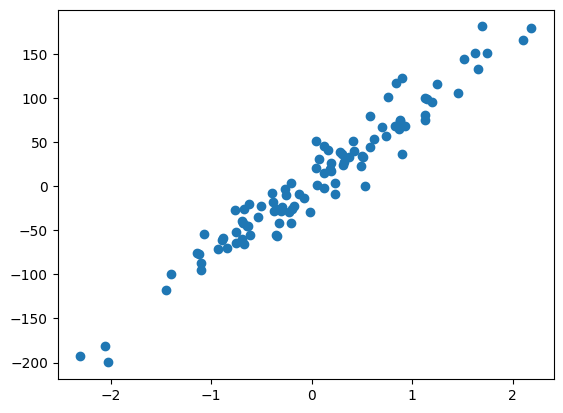

In [2]:
x,y = make_regression(
    n_samples = 100,
    n_features = 1,
    n_informative = 1,
    n_targets = 1,
    noise = 20,
    random_state = 1)

plt.scatter(x, y)

In [3]:
from sklearn.linear_model import LinearRegression
lr_model = LinearRegression()

lr_model.fit(x, y)

m = lr_model.coef_[0]
c = lr_model.intercept_ 
print(f"Slope(m): {m}")
print(f"Intercept(c): {c}")

Slope(m): 82.48449929280291
Intercept(c): 4.054028777621713


In [4]:
b = -520
m = 600
lr = 0.001

all_c = []   # changed from all_b
all_m = []
all_cost = []

epochs = 50

for i in range(epochs):
    slope_b = 0
    slope_m = 0
    cost = 0
    
    for j in range(x.shape[0]):   # changed X -> x
        slope_b = slope_b - 2*(y[j] - (m * x[j]) - b)
        slope_m = slope_m - 2*(y[j] - (m * x[j]) - b) * x[j]
        cost = cost + (y[j] - m * x[j] - b) ** 2

    b = b - (lr * slope_b)
    m = m - (lr * slope_m)
    
    all_c.append(b)   # updated here
    all_m.append(m)
    all_cost.append(cost)

# GD LEarning m and c over epochs

GIF saved at: 00 Visualizations_m_b\01_Viz_1.gif


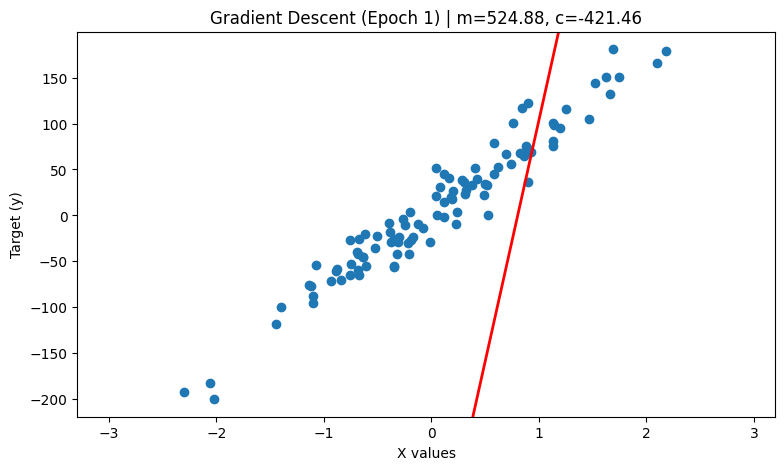

In [5]:
import os

fig, ax = plt.subplots(figsize=(9,5))

# Flatten x for plotting
x_flat = x.flatten()

x_i = np.arange(-3, 3, 0.1)

ax.scatter(x_flat, y)

# initial line
line, = ax.plot(x_i, x_i*50 - 4, 'r-', linewidth=2)

def update(i):
    epoch_num = i + 1
    
    m_val = all_m[i].item() if hasattr(all_m[i], "item") else all_m[i]
    c_val = all_c[i].item() if hasattr(all_c[i], "item") else all_c[i]
    
    line.set_ydata(x_i * m_val + c_val)
    
    ax.set_xlabel("X values")
    ax.set_ylabel("Target (y)")
    ax.set_title(f"Gradient Descent (Epoch {epoch_num}) | m={m_val:.2f}, c={c_val:.2f}")
    
    return line,

anim = FuncAnimation(fig, update, repeat=True, frames=epochs, interval=500)

# Correct folder and filename
folder_path = "00 Visualizations_m_b"
os.makedirs(folder_path, exist_ok=True)

gif_path = os.path.join(folder_path, "01_Viz_1.gif")

writergif = animation.PillowWriter(fps=2)
anim.save(gif_path, writer=writergif)

print(f"GIF saved at: {gif_path}")

# Cost V/S Epoch

GIF saved at: 00 Visualizations_m_b\02_Viz_2.gif


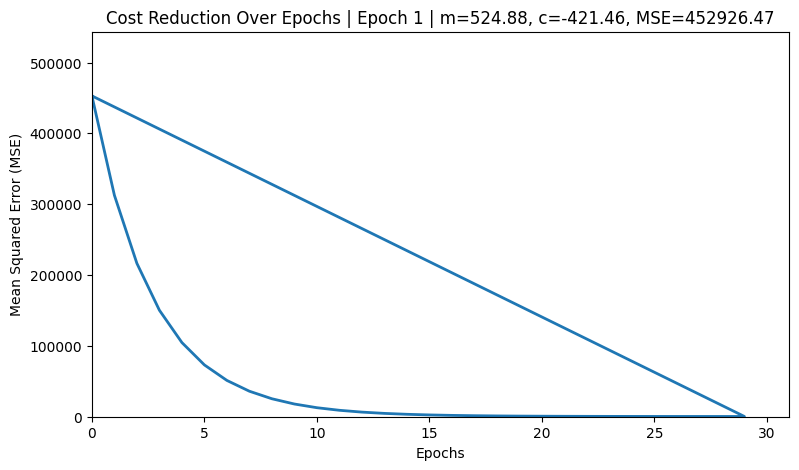

In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation

# Ensure x is 1D
x_flat = x.flatten()

num_epochs = list(range(30))

fig = plt.figure(figsize=(9,5))
axis = plt.axes(xlim=(0, 31), ylim=(0, max(all_cost)/len(x_flat) * 1.2))

line, = axis.plot([], [], lw=2)

xdata, ydata = [], []

def animate(i):
    epoch_num = i + 1

    xdata.append(num_epochs[i])

    mse = all_cost[i] / len(x_flat)
    ydata.append(mse)

    line.set_data(xdata, ydata)

    # 🔥 FORCE SCALARS (no ambiguity)
    m_val = np.asarray(all_m[i]).squeeze().item()
    c_val = np.asarray(all_c[i]).squeeze().item()
    mse_val = np.asarray(mse).item()

    axis.set_xlabel("Epochs")
    axis.set_ylabel("Mean Squared Error (MSE)")
    axis.set_title(
        f"Cost Reduction Over Epochs | Epoch {epoch_num} | "
        f"m={m_val:.2f}, c={c_val:.2f}, MSE={mse_val:.2f}"
    )

    return line,

anim = animation.FuncAnimation(
    fig,
    animate,
    frames=30,
    repeat=False,
    interval=500
)

# Save correctly
folder_path = "00 Visualizations_m_b"
os.makedirs(folder_path, exist_ok=True)

gif_path = os.path.join(folder_path, "02_Viz_2.gif")

writergif = animation.PillowWriter(fps=2)
anim.save(gif_path, writer=writergif)

print(f"GIF saved at: {gif_path}")

# Intercept Convergence

GIF saved at: 00 Visualizations_m_b\03_Viz_c_convergence.gif


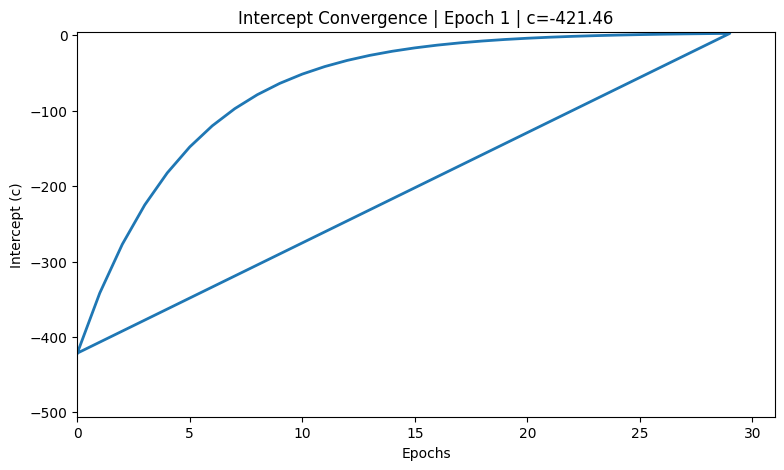

In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation

num_epochs = list(range(30))

fig = plt.figure(figsize=(9,5))
axis = plt.axes(xlim=(0, 31), ylim=(min(all_c)*1.2, max(all_c)*1.2))

line, = axis.plot([], [], lw=2)

xdata, ydata = [], []

def animate(i):
    epoch_num = i + 1

    xdata.append(num_epochs[i])

    # intercept (c)
    c_val = np.asarray(all_c[i]).squeeze().item()
    ydata.append(c_val)

    line.set_data(xdata, ydata)

    axis.set_xlabel("Epochs")
    axis.set_ylabel("Intercept (c)")
    axis.set_title(f"Intercept Convergence | Epoch {epoch_num} | c={c_val:.2f}")

    return line,

anim = animation.FuncAnimation(
    fig,
    animate,
    frames=30,
    repeat=False,
    interval=500
)

# Save properly
folder_path = "00 Visualizations_m_b"
os.makedirs(folder_path, exist_ok=True)

gif_path = os.path.join(folder_path, "03_Viz_c_convergence.gif")

writergif = animation.PillowWriter(fps=2)
anim.save(gif_path, writer=writergif)

print(f"GIF saved at: {gif_path}")

GIF saved at: 00 Visualizations_m_b\04_Viz_c_convergence_2.gif


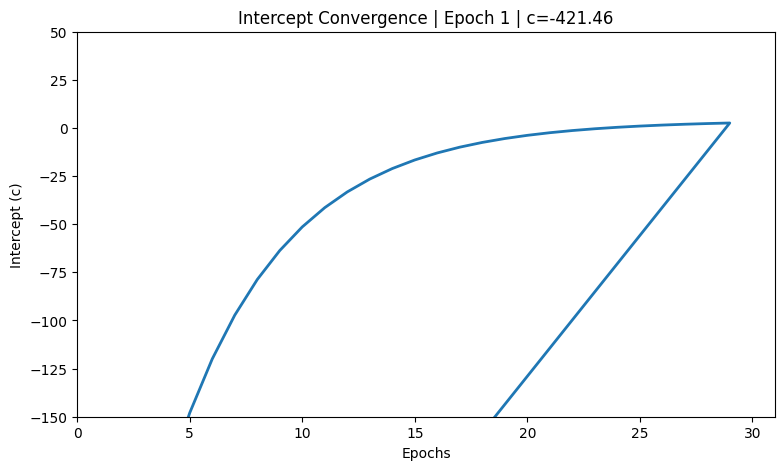

In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation

num_epochs = list(range(0, 30))

fig = plt.figure(figsize=(9,5))
axis = plt.axes(xlim=(0, 31), ylim=(-150, 50))

line, = axis.plot([], [], lw=2)

xdata, ydata = [], []

def animate(i):
    epoch_num = i + 1

    xdata.append(num_epochs[i])

    # intercept (c)
    c_val = np.asarray(all_c[i]).squeeze().item()
    ydata.append(c_val)

    line.set_data(xdata, ydata)

    axis.set_xlabel("Epochs")
    axis.set_ylabel("Intercept (c)")
    axis.set_title(f"Intercept Convergence | Epoch {epoch_num} | c={c_val:.2f}")

    return line,

anim = animation.FuncAnimation(
    fig,
    animate,
    frames=30,
    repeat=False,
    interval=500
)

# ✅ Save in same directory as before
folder_path = "00 Visualizations_m_b"
os.makedirs(folder_path, exist_ok=True)

gif_path = os.path.join(folder_path, "04_Viz_c_convergence_2.gif")

writergif = animation.PillowWriter(fps=2)
anim.save(gif_path, writer=writergif)

print(f"GIF saved at: {gif_path}")

# Contour plot

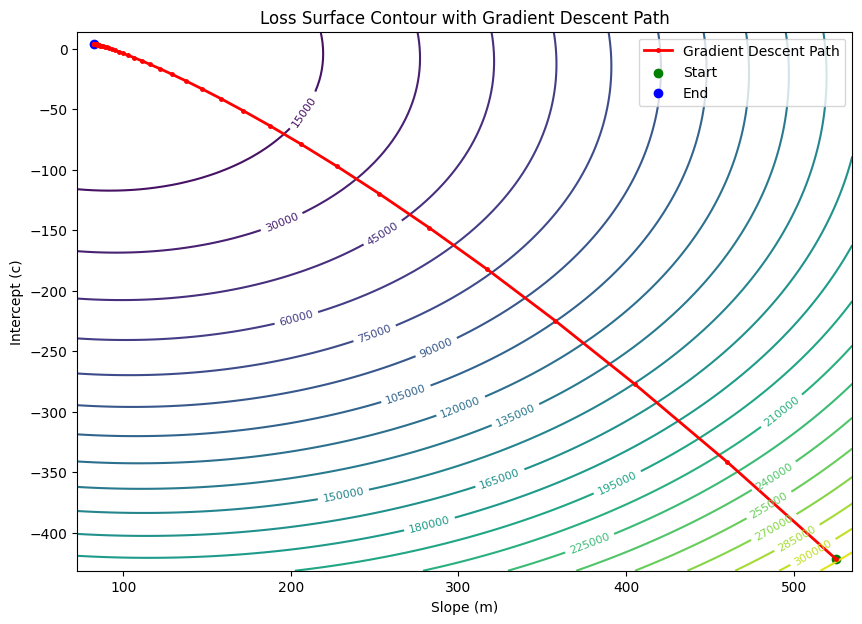

Contour plot saved at: 00 Visualizations_m_b\07_Contour_Plot.png


In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Convert data properly
# -----------------------------
x_flat = x.flatten()
y_flat = y.flatten()

# -----------------------------
# Cost function
# -----------------------------
def compute_cost(m, c):
    y_pred = m * x_flat + c
    return np.mean((y_flat - y_pred) ** 2)

# -----------------------------
# Create grid for m and c
# -----------------------------
m_vals = np.linspace(min(all_m)-10, max(all_m)+10, 100)
c_vals = np.linspace(min(all_c)-10, max(all_c)+10, 100)

M, C = np.meshgrid(m_vals, c_vals)

Z = np.zeros_like(M)

for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        Z[i, j] = compute_cost(M[i, j], C[i, j])

# -----------------------------
# Plot contour
# -----------------------------
plt.figure(figsize=(10,7))

contours = plt.contour(M, C, Z, levels=30)
plt.clabel(contours, inline=True, fontsize=8)

# -----------------------------
# Gradient descent path
# -----------------------------
plt.plot(all_m, all_c, 'r.-', linewidth=2, markersize=5, label="Gradient Descent Path")

plt.scatter(all_m[0], all_c[0], color='green', label="Start")
plt.scatter(all_m[-1], all_c[-1], color='blue', label="End")

# -----------------------------
# Labels
# -----------------------------
plt.title("Loss Surface Contour with Gradient Descent Path")
plt.xlabel("Slope (m)")
plt.ylabel("Intercept (c)")
plt.legend()

# -----------------------------
# Save figure
# -----------------------------
folder_path = "00 Visualizations_m_b"
os.makedirs(folder_path, exist_ok=True)

file_path = os.path.join(folder_path, "07_Contour_Plot.png")

plt.savefig(file_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Contour plot saved at: {file_path}")